## Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))

from src.pipeline import run_pipeline
from src.transform import daten_transformieren, DICHTEKLASSEN

daten = daten_transformieren(run_pipeline())

ANTRIEBE = ["Elektro", "Hybrid", "Benzin", "Diesel"]
FARBEN = {"Elektro": "#2a78d6", "Hybrid": "#eb6834", "Benzin": "#1baf7a", "Diesel": "#eda100"}
FARBEN_DICHTE = dict(zip(DICHTEKLASSEN, ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]))

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e5e5e5",
    "lines.linewidth": 2,
})


def linien_beschriften(ax, tabelle):
    """Schreibt den Namen jeder Linie an ihr Ende."""
    for spalte in tabelle.columns:
        ax.annotate(spalte, (tabelle.index[-1], tabelle[spalte].iloc[-1]),
                    xytext=(6, 0), textcoords="offset points", va="center", color="#333333")

## Antriebsarten in der Schweiz

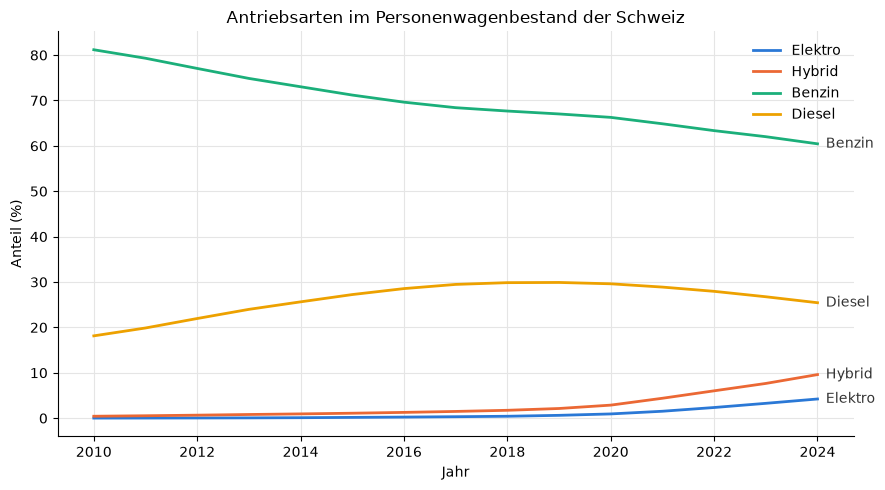

In [2]:
total = daten.groupby(["Jahr", "Antriebsart"])["Fahrzeuge"].sum().unstack()
anteile_ch = total[ANTRIEBE].div(total.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots()
for antrieb in ANTRIEBE:
    ax.plot(anteile_ch.index, anteile_ch[antrieb], color=FARBEN[antrieb], label=antrieb)
linien_beschriften(ax, anteile_ch)
ax.set(title="Antriebsarten im Personenwagenbestand der Schweiz", xlabel="Jahr", ylabel="Anteil (%)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## Elektroanteil nach Dichteklasse

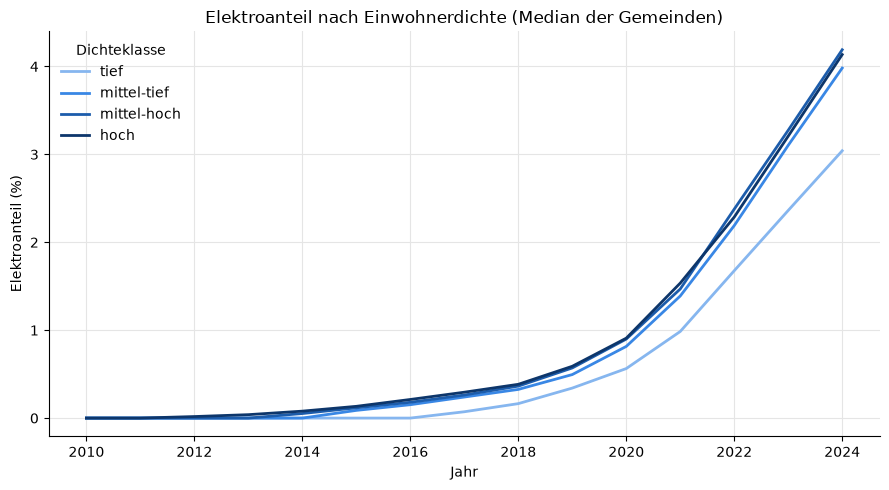

In [3]:
elektro = daten[daten["Antriebsart"] == "Elektro"]
elektro_dichte = elektro.groupby(["Jahr", "Dichteklasse"], observed=True)["Anteil"].median().unstack()

fig, ax = plt.subplots()
for klasse in DICHTEKLASSEN:
    ax.plot(elektro_dichte.index, elektro_dichte[klasse], color=FARBEN_DICHTE[klasse], label=klasse)
ax.set(title="Elektroanteil nach Einwohnerdichte (Median der Gemeinden)", xlabel="Jahr", ylabel="Elektroanteil (%)")
ax.legend(title="Dichteklasse", frameon=False)
plt.tight_layout()
plt.show()

## Alle Antriebe nach Einwohnerdichte 2010 gegenüber 2024

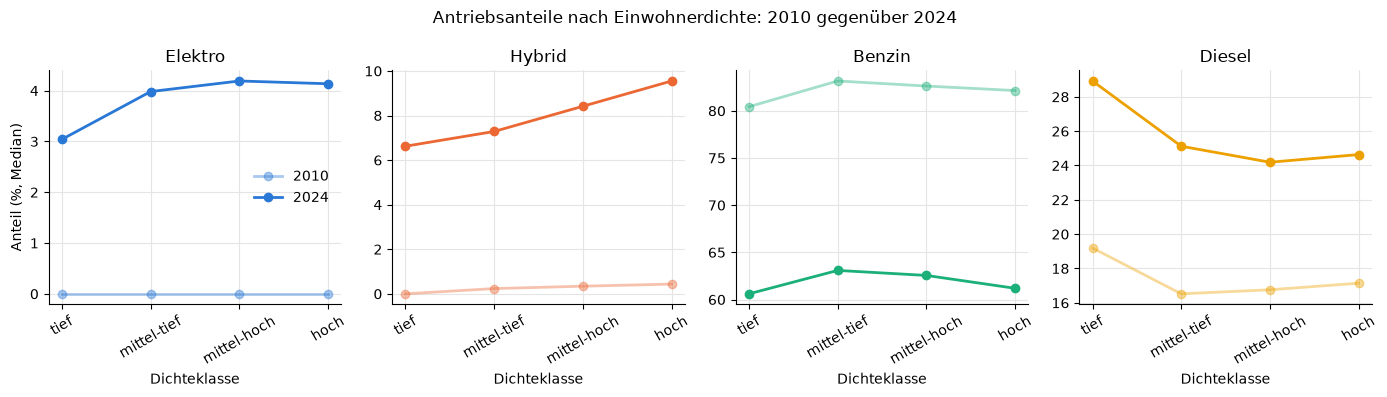

In [4]:
vergleich = (
    daten[daten["Jahr"].isin([2010, 2024]) & daten["Antriebsart"].isin(ANTRIEBE)]
    .groupby(["Antriebsart", "Jahr", "Dichteklasse"], observed=True)["Anteil"]
    .median()
)

fig, achsen = plt.subplots(1, 4, figsize=(14, 4))
for ax, antrieb in zip(achsen, ANTRIEBE):
    for jahr, deckkraft in [(2010, 0.4), (2024, 1.0)]:
        werte = vergleich[antrieb][jahr][DICHTEKLASSEN]
        ax.plot(DICHTEKLASSEN, werte, marker="o", color=FARBEN[antrieb], alpha=deckkraft, label=str(jahr))
    ax.set(title=antrieb, xlabel="Dichteklasse")
    ax.tick_params(axis="x", rotation=30)
achsen[0].set_ylabel("Anteil (%, Median)")
achsen[0].legend(frameon=False)
fig.suptitle("Antriebsanteile nach Einwohnerdichte: 2010 gegenüber 2024")
plt.tight_layout()
plt.show()